In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

df = pd.read_csv("../data/creditcard.csv")
print(f"Shape: {df.shape}")
print(f"Missing: {df.isnull().sum().sum()}")
print(f"Time range: {df['Time'].min()} ~ {df['Time'].max()} ({(df['Time'].max()-df['Time'].min())/3600:.1f} hours)")
print(df['Class'].value_counts())

Shape: (284807, 31)
Missing: 0
Time range: 0.0 ~ 172792.0 (48.0 hours)
Class
0    284315
1       492
Name: count, dtype: int64


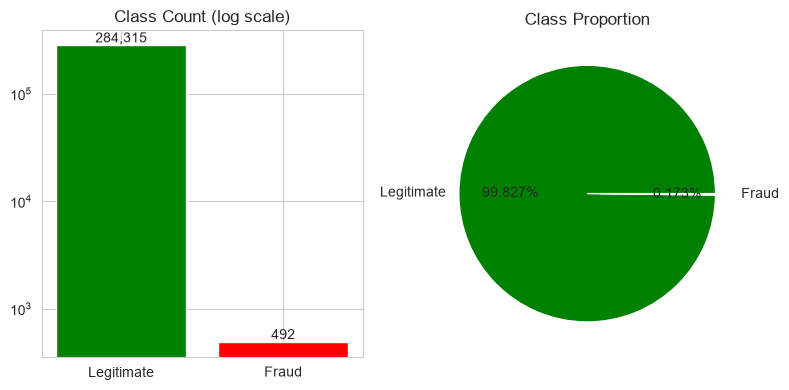

Imbalance ratio: 577.9 : 1


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
counts = df['Class'].value_counts()
ax[0].bar(['Legitimate', 'Fraud'], counts.values, color=['green', 'red'])
ax[0].set_yscale('log')
ax[0].set_title('Class Count (log scale)')
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f'{v:,}', ha='center', va='bottom')

ax[1].pie(counts.values, labels=['Legitimate', 'Fraud'], autopct='%1.3f%%', 
        colors=['green', 'red'], explode=[0, 0.1])
ax[1].set_title('Class Proportion')
plt.tight_layout()
plt.show()

print(f"Imbalance ratio: {counts[0]/counts[1]:.1f} : 1")

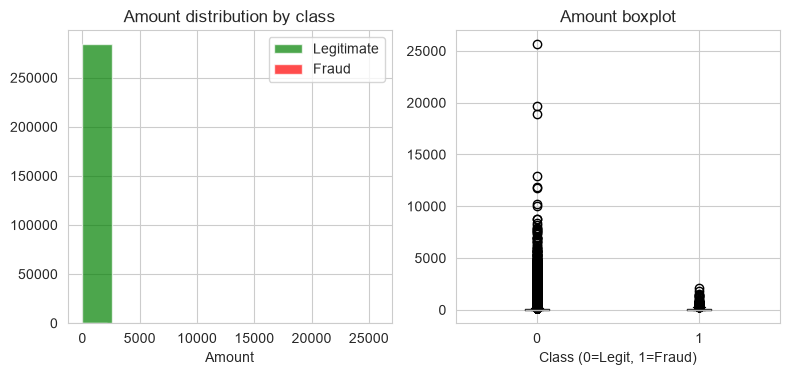

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
df[df['Class']==0]['Amount'].hist(bins=10, alpha=0.7, label='Legitimate', 
                                    ax=ax[0], color='green')
df[df['Class']==1]['Amount'].hist(bins=10, alpha=0.7, label='Fraud', 
                                    ax=ax[0], color='red')
ax[0].set_title('Amount distribution by class')
ax[0].set_xlabel('Amount')
ax[0].legend()

df.boxplot(column='Amount', by='Class', ax=ax[1])
ax[1].set_title('Amount boxplot')
ax[1].set_xlabel('Class (0=Legit, 1=Fraud)')
plt.suptitle('')
plt.tight_layout()
plt.show()

print(df.groupby('Class')['Amount'].describe())

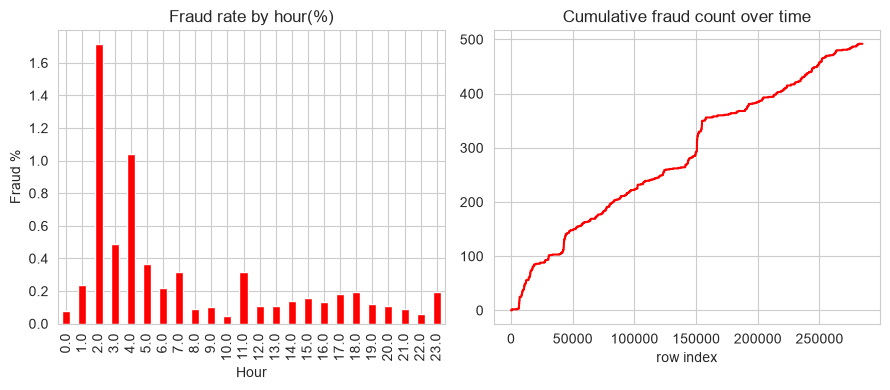

In [32]:
df['Hour'] = (df['Time'] // 3600) % 24

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
df.groupby('Hour')['Class'].mean().mul(100).plot(kind='bar', ax=ax[0], color='red')
ax[0].set_title('Fraud rate by hour(%)')
ax[0].set_xlabel('Hour')
ax[0].set_ylabel('Fraud %')

df['Class'].cumsum().plot(ax=ax[1], color='red')
ax[1].set_title('Cumulative fraud count over time')
ax[1].set_xlabel('row index')
plt.tight_layout()
plt.show()

Top 10 correlation with Class:
V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
Name: Class, dtype: float64


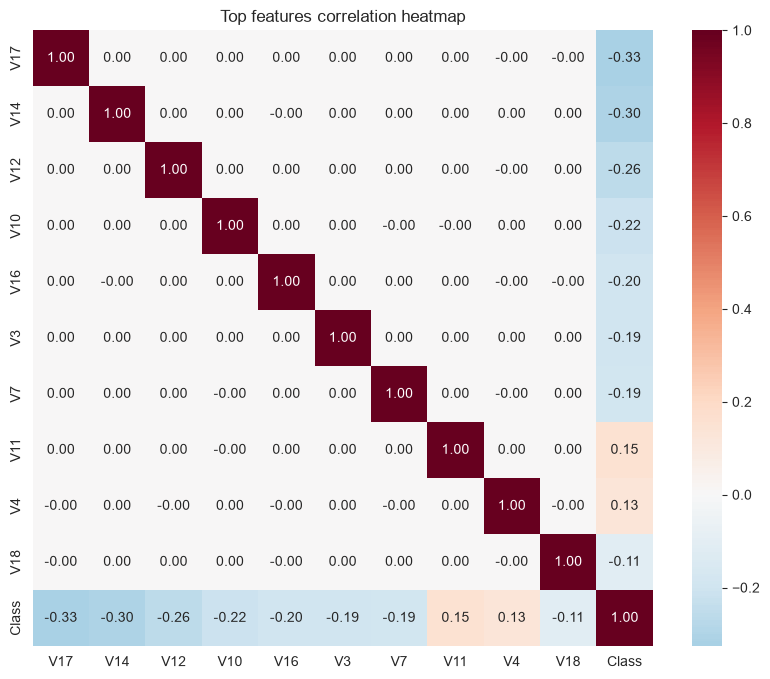

In [34]:
corr = df.corr()['Class'].drop('Class').abs().sort_values(ascending=False)
print("Top 10 correlation with Class:")
print(corr.head(10))

top_feats = corr.head(10).index.tolist() + ['Class']
plt.figure(figsize=(10, 8))
sns.heatmap(df[top_feats].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Top features correlation heatmap')
plt.show()